# 06 - Ensemble detector, severity scoring and alert de-duplication (Day 12)

**Question:** does stacking the four detectors (statistical, Isolation Forest, LSTM autoencoder, LSTM classifier)
with a LightGBM meta-learner detect anomalies better than the best single detector and better than a plain
weighted average - and does the severity / de-duplication layer turn the detections into a manageable alert stream?

Design (`src/models/ensemble_detector.py`):

* **Level 1** - the four `AnomalyScore`s of an event (`0.5` = each detector's own decision boundary).
* **Level 2** - `MetaLearner` (LightGBM) on 10 features: 4 scores, 4 confidences, the entity's historical anomaly rate and the
  hour of day. Monotone `+1` constraint on the four scores, random member dropout during training so a warming-up or
  missing detector does not break it. The fallback is the weighted average `0.2 / 0.3 / 0.25 / 0.25`.
* The stacker's probability is mapped piecewise-linearly so that its F1-optimal threshold lands on `0.5`; the severity
  thresholds (0.3 / 0.6 / 0.85) therefore mean the same thing whichever way the ensemble is produced.

**Protocol (no leakage).** Three *independent* simulations (different seeds and days, same generator):
the base detectors train on **A**, the meta-learner is fitted - with 5-fold cross-validation grouped by sensor - on **B**
(the held-out labelled data the base models never saw) and everything is reported on **C**.

In [1]:
import sys, os, time, logging, warnings
from pathlib import Path
from datetime import datetime, UTC, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
logging.getLogger("src").setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

from IPython.display import Markdown, display
from src.models.offline_dataset import simulate_labeled_features
from src.models.feature_engineering import OnlineScaler
from src.models.lstm_autoencoder import make_sequences, select_features, train_detector
from src.models.lstm_classifier import DatasetBuilder, train_classifier
from src.models.isolation_forest_detector import IsolationForestDetector
from src.models.statistical_detector import UnifiedStatisticalDetector
from src.models.model_registry import ModelRegistry
from src.models.ensemble_detector import (
    MEMBERS, META_FEATURE_NAMES, AlertDeduplicator, AnomalyEvent, EnsembleAnomalyScore, EnsembleDetector,
    EntityContext, MetaLearner, Severity, SeverityScorer, binary_metrics, build_anomaly_event, collect_member_scores,
)
from src.utils.config import LSTMClassifierConfig, get_config

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
PAL = sns.color_palette("colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
cfg = get_config()
SEED, EPOCHS = 7, 15          # spec trains longer; shortened so the notebook runs in ~15 minutes on a CPU
BASE_H, SEG_H = 10, 6         # simulated hours: base training / meta-learner / test
LABELS = {"statistical": "Statistical", "isolation_forest": "Isolation Forest", "lstm_autoencoder": "LSTM-AE",
          "lstm_classifier": "LSTM-Cls", "weighted": "Weighted avg", "stacked": "Stacked (LightGBM)"}
print(f"ensemble weights (config): {cfg.models.ensemble.model_dump()}")

ensemble weights (config): {'statistical_weight': 0.2, 'isolation_forest_weight': 0.3, 'lstm_autoencoder_weight': 0.25, 'lstm_classifier_weight': 0.25, 'meta_learner_holdout': 0.2, 'cv_folds': 5}


## 1. Data

Contextual anomalies are only injected between 00:00 and 05:00, so each simulation starts a few hours before that window.
Features come from the production path (simulator -> windowed aggregator -> feature engineer), so there is no train/serve skew.

In [2]:
D = lambda day, h: datetime(2026, 11, day, h, 0, tzinfo=UTC)
t0 = time.time()
sims = {
    "A: base training": simulate_labeled_features(BASE_H * 3600, start_time=D(20, 19), seed=7)["warehouse"],
    "B: meta-learner (held out)": simulate_labeled_features(SEG_H * 3600, start_time=D(21, 22), seed=11)["warehouse"],
    "C: test": simulate_labeled_features(SEG_H * 3600, start_time=D(22, 22), seed=13)["warehouse"],
}
base, meta, test = sims.values()
rows = []
for name, ds in sims.items():
    c = ds.type_counts()
    rows.append({"simulation": name, "events": len(ds), "anomaly rate": ds.anomaly_rate, **{k: c.get(k, 0) for k in ("point", "contextual", "collective")}})
display(pd.DataFrame(rows).set_index("simulation").style.format({"events": "{:,}", "anomaly rate": "{:.2%}"}))
print(f"simulated in {time.time() - t0:.0f}s; {len(base.feature_names)} features, {len(set(base.entity_ids))} sensors")

,events,anomaly rate,point,contextual,collective
simulation,,,,,
A: base training,"432,000",4.78%,8334,10085,2214
B: meta-learner (held out),"259,200",5.47%,4800,8192,1199
C: test,"259,200",5.31%,4806,7729,1236


simulated in 87s; 30 features, 12 sensors


## 2. Base detectors (trained on A only)

* Statistical: `UnifiedStatisticalDetector.production()` (no training, adapts online).
* Isolation Forest: fitted on warm rows of A (every 5th row, contamination 3%).
* LSTM autoencoder: trained on **normal** windows of A, clock features excluded (as in notebook 04).
* LSTM classifier: trained on A with class weights + SMOTE (as in notebook 05).

All neural models use one scaler fitted on the warm normal rows of A.

In [3]:
names = tuple(base.feature_names)
scaler = OnlineScaler(len(names), clip=10.0)
scaler.fit_update(base.subset(base.warm & ~base.y).X)

t0 = time.time()
forest = IsolationForestDetector(names, source_type="warehouse", contamination=0.03, n_estimators=200, random_state=SEED).fit(base.X[base.warm][::5])
print(f"Isolation Forest fitted ({time.time() - t0:.0f}s)")

ae_names, cols = select_features(names)
W = make_sequences(base, scaler, seq_len=cfg.models.lstm_autoencoder.seq_len, stride=10, columns=cols)
Wn = W.subset(W.normal); cut = np.quantile(Wn.end_timestamps, 0.8)
trn, val = Wn.subset(Wn.end_timestamps < cut), Wn.subset(Wn.end_timestamps >= cut)
t0 = time.time()
ae, ae_hist = train_detector(trn.x, val.x, ae_names, cfg.models.lstm_autoencoder.model_copy(update={"max_epochs": EPOCHS}), columns=cols, log_dir=None)
ae.mc_passes = 3     # 3 MC-dropout passes instead of 10: the ensemble only needs the mean error here
print(f"LSTM autoencoder: {ae_hist.epochs_run} epochs in {time.time() - t0:.0f}s (best epoch {ae_hist.best_epoch})")

data = DatasetBuilder(stride=10, smote_ratio=0.3, seed=SEED).build(base, scaler)
t0 = time.time()
clf, clf_hist = train_classifier(data, LSTMClassifierConfig(max_epochs=EPOCHS, early_stopping_patience=8, batch_size=128), log_dir=None, num_workers=0, seed=SEED)
print(f"LSTM classifier: {clf_hist.epochs_run} epochs in {time.time() - t0:.0f}s (best epoch {clf_hist.best_epoch}, val macro-F1 {clf_hist.best_score:.3f})")

Isolation Forest fitted (1s)


LSTM autoencoder: 15 epochs in 316s (best epoch 15)


LSTM classifier: 15 epochs in 208s (best epoch 15, val macro-F1 0.839)


## 3. Member score tables

`collect_member_scores` scores one event every 10 rows per sensor (the window ends of the longest-window model) with all four detectors
and joins the results. The statistical detector is stateful, so it streams over **every** row in order and a fresh instance is used for
each simulation (a cold start, as after a restart). The neural windows are standardised with the same scaler as in training.

In [4]:
t0 = time.time()
def table(ds):
    return collect_member_scores(ds, scaler, statistical=UnifiedStatisticalDetector.production(), isolation_forest=forest,
                                 lstm_autoencoder=ae, lstm_classifier=clf, stride=10)
tab_meta, tab_test = table(meta), table(test)
print(f"scored in {time.time() - t0:.0f}s: B {len(tab_meta):,} events ({tab_meta.y.sum()} anomalies), C {len(tab_test):,} events ({tab_test.y.sum()} anomalies)")
cover = pd.DataFrame({LABELS[m]: [np.isfinite(tab_test.scores[:, i]).mean()] for i, m in enumerate(MEMBERS)}, index=["share of test events scored"])
display(cover.style.format("{:.1%}"))

scored in 84s: B 24,888 events (1456 anomalies), C 24,888 events (1323 anomalies)


,Statistical,Isolation Forest,LSTM-AE,LSTM-Cls
share of test events scored,100.0%,100.0%,100.0%,100.0%


## 4. Fitting the meta-learner on B

5-fold cross-validation, **grouped by sensor** (neighbouring readings of one sensor are nearly identical, so a random split would leak).
The out-of-fold probabilities choose the operating threshold; the final model is then fitted on all of B.

out-of-fold on B (5 folds, grouped=True): F1 0.746, precision 0.849, recall 0.666, AP 0.797, ROC-AUC 0.942; threshold 0.380


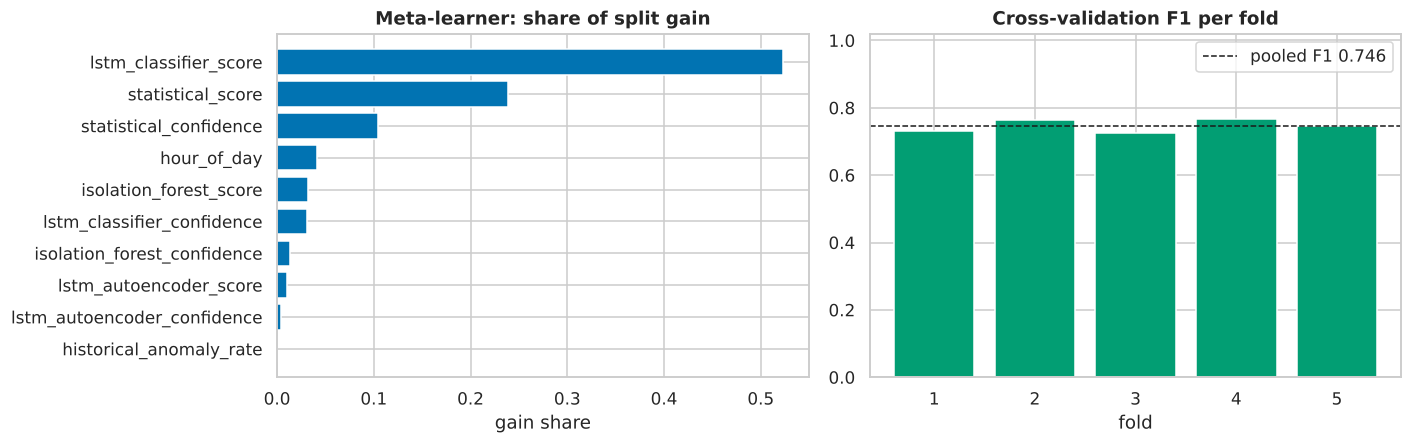

In [5]:
ens = EnsembleDetector.from_config(cfg.models.ensemble)
weighted = EnsembleDetector.from_config(cfg.models.ensemble)          # same weights, no stacker: the fallback
rep = ens.fit_meta_learner(tab_meta)
print(f"out-of-fold on B ({rep.n_folds} folds, grouped={rep.grouped}): F1 {rep.f1:.3f}, precision {rep.precision:.3f}, recall {rep.recall:.3f}, "
      f"AP {rep.average_precision:.3f}, ROC-AUC {rep.roc_auc:.3f}; threshold {rep.threshold:.3f}")

imp = pd.Series(ens.meta_learner.feature_importance()).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(imp.index, imp.values, color=PAL[0]); ax[0].set(title="Meta-learner: share of split gain", xlabel="gain share")
ax[1].bar(range(1, rep.n_folds + 1), rep.fold_f1, color=PAL[2]); ax[1].axhline(rep.f1, color="k", ls="--", lw=1, label=f"pooled F1 {rep.f1:.3f}")
ax[1].set(title="Cross-validation F1 per fold", xlabel="fold", ylim=(0, 1.02)); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Held-out test (C): ensemble vs every single detector

Each single detector is judged at **its own** decision boundary (`score >= 0.5`), exactly what it would raise in production. The last column,
*oracle F1*, is the best F1 any threshold could reach on the test set itself - an upper bound that no deployed system can use; it separates
"the scores rank well" from "the threshold is well chosen".

,precision,recall,f1,false_positive_rate,average_precision,roc_auc,oracle_f1,n_flagged
Statistical,0.319,0.493,0.387,0.059,0.551,0.888,0.564,2046
Isolation Forest,0.609,0.384,0.471,0.014,0.472,0.815,0.475,834
LSTM-AE,0.080,0.520,0.139,0.336,0.072,0.629,0.141,8597
LSTM-Cls,0.466,0.634,0.537,0.041,0.645,0.848,0.637,1802
Weighted avg,0.810,0.457,0.585,0.006,0.629,0.870,0.605,747
Stacked (LightGBM),0.910,0.607,0.728,0.003,0.775,0.932,0.739,882


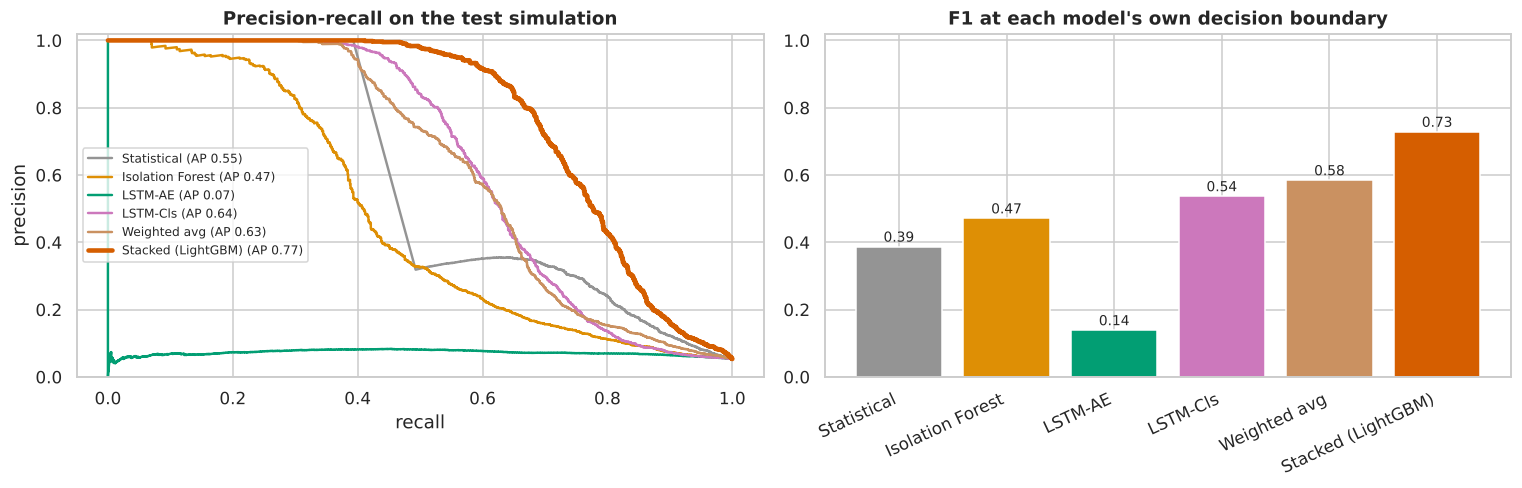

In [6]:
y = tab_test.y
scores = {m: tab_test.scores[:, i] for i, m in enumerate(MEMBERS)}
scores["weighted"] = weighted.score_table(tab_test)
scores["stacked"] = ens.score_table(tab_test)

def oracle_f1(s):
    s = np.nan_to_num(s, nan=0.0); p, r, _ = precision_recall_curve(y, s)
    return float(np.max(2 * p * r / np.maximum(p + r, 1e-12)))

res = pd.DataFrame({LABELS[k]: {**binary_metrics(y, v), "oracle_f1": oracle_f1(v)} for k, v in scores.items()}).T
res = res[["precision", "recall", "f1", "false_positive_rate", "average_precision", "roc_auc", "oracle_f1", "n_flagged"]]
display(res.style.format({c: "{:.3f}" for c in res.columns if c != "n_flagged"} | {"n_flagged": "{:.0f}"}).highlight_max(subset=["f1", "average_precision", "roc_auc", "oracle_f1"], color="#c7e9c0"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
colors = dict(zip(scores, [PAL[7], PAL[1], PAL[2], PAL[4], PAL[5], PAL[3]]))
for k, v in scores.items():
    p, r, _ = precision_recall_curve(y, np.nan_to_num(v, nan=0.0))
    ax[0].plot(r, p, color=colors[k], lw=3 if k == "stacked" else 1.6, label=f"{LABELS[k]} (AP {res.loc[LABELS[k], 'average_precision']:.2f})")
ax[0].set(title="Precision-recall on the test simulation", xlabel="recall", ylabel="precision", ylim=(0, 1.02)); ax[0].legend(fontsize=8)
ax[1].bar(res.index, res["f1"], color=[colors[k] for k in scores]); ax[1].set(title="F1 at each model's own decision boundary", ylim=(0, 1.02))
for i, v in enumerate(res["f1"]): ax[1].text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
plt.setp(ax[1].get_xticklabels(), rotation=25, ha="right"); plt.tight_layout(); plt.show()

### Where does the ensemble help? Recall by anomaly type, and what it costs

In [7]:
kinds = ["point", "contextual", "collective"]
flag = {k: np.nan_to_num(v, nan=0.0) >= 0.5 for k, v in scores.items()}
truth = tab_test.anomaly_type.astype(str)
rec = pd.DataFrame({LABELS[k]: [flag[k][(truth == t)].mean() for t in kinds] + [flag[k][~y].mean()] for k in scores}, index=kinds + ["FALSE-ALARM RATE (normal events)"])
display(rec.style.format("{:.1%}").highlight_max(subset=pd.IndexSlice[kinds, :], axis=1, color="#c7e9c0"))
print("windows per type:", {t: int((truth == t).sum()) for t in kinds}, "| normal:", int((~y).sum()))

,Statistical,Isolation Forest,LSTM-AE,LSTM-Cls,Weighted avg,Stacked (LightGBM)
point,100.0%,98.5%,77.8%,100.0%,100.0%,100.0%
contextual,19.8%,5.1%,37.1%,43.7%,15.8%,39.9%
collective,35.5%,11.6%,44.6%,43.8%,20.7%,37.2%
FALSE-ALARM RATE (normal events),5.9%,1.4%,33.6%,4.1%,0.6%,0.3%


windows per type: {'point': 463, 'contextual': 739, 'collective': 121} | normal: 23565


### Predicted anomaly type

In [8]:
pred = ens.predict_types(tab_test)
hit = y & (scores["stacked"] >= 0.5)
conf = pd.crosstab(pd.Series(truth[hit], name="true type"), pd.Series(pred[hit].astype(str), name="predicted type"))
display(conf)
acc = (truth[hit] == pred[hit].astype(str)).mean()
print(f"type accuracy on detected anomalies: {acc:.1%} ({int(hit.sum())} detected)")

predicted type,collective,contextual,point
true type,,,
collective,13,28,4
contextual,45,238,12
point,0,12,451


type accuracy on detected anomalies: 87.4% (803 detected)


## 6. Severity scoring

Entities are mapped to a business class from their id (`wh*-A-temp-*` is the cold-storage temperature sensor; everything else uses the
default weight 0.5 - the other two classes need vehicle / inventory events, which `EntityContext.from_event` handles in production).
The score is `ensemble x impact x time-factor x asset-factor`, so a default-impact sensor can never be rated above what its weight allows.

In [9]:
scorer = SeverityScorer.from_config(cfg.alerts)
def context_of(entity):
    parts = str(entity).split("-")
    cold = parts[1] == "A" and parts[2] == "temp"
    return EntityContext(entity_type="warehouse_sensor", impact_key="cold_storage_temp" if cold else "default", zone=parts[1],
                         sensor_type="temperature" if parts[2] == "temp" else "humidity")

detected = np.flatnonzero(scores["stacked"] >= 0.5)
sev_rows = []
for i in detected:
    stamp = datetime.fromtimestamp(float(tab_test.timestamps[i]), UTC)
    e = EnsembleAnomalyScore(str(tab_test.entity_ids[i]), stamp, float(scores["stacked"][i]), {}, pred[i], abs(2 * scores["stacked"][i] - 1), True)
    r = scorer.score(e, context_of(tab_test.entity_ids[i]))
    sev_rows.append({"class": "cold-storage temp" if r.business_impact == 1.0 else "other", "level": r.level.name, "score": r.score, "true_anomaly": bool(y[i])})
sev = pd.DataFrame(sev_rows)
order = ["INFO", "WARNING", "CRITICAL", "EMERGENCY"]
display(pd.crosstab(sev["class"], sev["level"]).reindex(columns=order, fill_value=0))
print("share of INFO/WARNING among FALSE alarms:", f"{sev[~sev.true_anomaly].level.isin(['INFO','WARNING']).mean():.0%}" if (~sev.true_anomaly).any() else "no false alarms",
      "| among true detections:", f"{sev[sev.true_anomaly].level.isin(['INFO','WARNING']).mean():.0%}")
example = scorer.score(0.95, context_of("wh1-A-temp-01"), timestamp=D(23, 2), anomaly_type="collective")
print(f"\nexample, cold-storage drift at 02:00: {example.level.name} (score {example.score:.2f})\n -> {example.recommended_action}")

level,INFO,WARNING,CRITICAL,EMERGENCY
class,,,,
cold-storage temp,0,18,32,99
other,77,656,0,0


share of INFO/WARNING among FALSE alarms: 92% | among true detections: 84%

example, cold-storage drift at 02:00: EMERGENCY (score 0.95)
 -> IMMEDIATE ACTION: temperature is drifting: schedule a refrigeration inspection and recalibrate the sensor; prepare to relocate stock if the drift continues.


## 7. Alert de-duplication and escalation

Replaying the detections of the test simulation in time order (one every ~10 s per sensor because the table is strided) as `AnomalyEvent`s
through the `AlertDeduplicator` (5 minute window, escalation after 10 minutes).

In [10]:
dedup = AlertDeduplicator.from_config(cfg.alerts)
published, raw_n = [], 0
for i in detected:
    stamp = datetime.fromtimestamp(float(tab_test.timestamps[i]), UTC)
    e = EnsembleAnomalyScore(str(tab_test.entity_ids[i]), stamp, float(scores["stacked"][i]), {}, pred[i] or "point", abs(2 * scores["stacked"][i] - 1), True)
    ctx = context_of(tab_test.entity_ids[i])
    ev = build_anomaly_event(e, scorer.score(e, ctx), ctx)
    raw_n += 1
    out = dedup.process(ev)
    if out is not None:
        published.append(out)
st = dedup.stats()
print(f"{raw_n:,} detections -> {st['emitted']:,} published alerts ({1 - st['emitted'] / raw_n:.0%} fewer), {st['suppressed']:,} suppressed, "
      f"{st['escalated']} escalations, {st['episodes']} episodes")
back = AnomalyEvent.from_dict(published[0].to_dict()) if published else None
print("JSON round-trip of an alert is lossless:", back == published[0] if back else "n/a")
esc = [e for e in published if e.escalated_from is not None]
if esc:
    print(f"\nexample escalation: {esc[0].entity_id} {esc[0].escalated_from.name} -> {esc[0].severity.name}, {esc[0].occurrence_count} detections in the episode")

882 detections -> 464 published alerts (47% fewer), 418 suppressed, 45 escalations, 291 episodes
JSON round-trip of an alert is lossless: True

example escalation: wh1-C-hum-01 WARNING -> CRITICAL, 7 detections in the episode


## 8. Persistence

In [11]:
registry = ModelRegistry(ROOT / "model_registry")
version = ens.save_meta_learner(registry, metrics={"test_f1": float(res.loc[LABELS["stacked"], "f1"]), "test_average_precision": float(res.loc[LABELS["stacked"], "average_precision"])},
                                extra={"notebook": "notebooks/06_ensemble_evaluation.ipynb", "protocol": "A train / B meta (5-fold CV grouped by sensor) / C test, independent simulations"})
restored = EnsembleDetector.from_config(cfg.models.ensemble); restored.load_meta_learner(registry, version.version)
same = np.allclose(restored.score_table(tab_test), scores["stacked"])
print(f"saved {version.model_type}/{version.version}; reloaded ensemble reproduces the test scores: {same}")

saved ensemble_meta_learner/20261123T114627100075Z; reloaded ensemble reproduces the test scores: True


In [12]:
st_, wa = res.loc[LABELS["stacked"]], res.loc[LABELS["weighted"]]
single = res.loc[[LABELS[m] for m in MEMBERS]]
best_single = single.f1.idxmax(); bs = single.loc[best_single]
best_rank = single.oracle_f1.idxmax(); br = single.loc[best_rank]; ae_row = res.loc[LABELS["lstm_autoencoder"]]
display(Markdown(f"""
## 9. Findings (test simulation C, {len(tab_test):,} events, {int(y.sum())} anomalous)

| | F1 | precision | recall | false-alarm rate | AP | oracle F1 |
|---|---|---|---|---|---|---|
| best single detector at its own boundary ({best_single}) | {bs.f1:.3f} | {bs.precision:.3f} | {bs.recall:.3f} | {bs.false_positive_rate:.2%} | {bs.average_precision:.3f} | {bs.oracle_f1:.3f} |
| weighted average (fallback) | {wa.f1:.3f} | {wa.precision:.3f} | {wa.recall:.3f} | {wa.false_positive_rate:.2%} | {wa.average_precision:.3f} | {wa.oracle_f1:.3f} |
| **stacked ensemble** | **{st_.f1:.3f}** | {st_.precision:.3f} | {st_.recall:.3f} | {st_.false_positive_rate:.2%} | {st_.average_precision:.3f} | {st_.oracle_f1:.3f} |

**What the numbers say**

* The stacker improves both *ranking* and the *operating point*. Ranking: AP {st_.average_precision:.3f} vs {br.average_precision:.3f} for the best single ranker
  ({best_rank}) and an oracle F1 of {st_.oracle_f1:.3f} vs {br.oracle_f1:.3f}. Operating point: its F1 at the deployed boundary ({st_.f1:.3f}) is within
  {st_.oracle_f1 - st_.f1:.3f} of its oracle, while {best_single} reaches {bs.f1:.3f} against an oracle of {bs.oracle_f1:.3f}. Part of that second gain is that the
  stacker's threshold was tuned on B and the single detectors' boundaries were not.
* The gain is **precision, not recall**: the false-alarm rate falls from {bs.false_positive_rate:.2%} ({best_single}) to {st_.false_positive_rate:.2%}, but recall ({st_.recall:.2f}) is
  not above the best single detector's ({bs.recall:.2f}). Point anomalies are caught almost perfectly; contextual and collective ones only about 40% of the time
  (section 5), so the ensemble inherits the weakness of its detectors there. Improving the LSTM autoencoder is the obvious lever.
* The LSTM autoencoder is the weak member here (ROC-AUC {ae_row.roc_auc:.2f}, false-alarm rate {ae_row.false_positive_rate:.0%}) after {EPOCHS} epochs; the meta-learner learns to
  down-weight it, which is why fusing four scores beats averaging them.
* The meta-learner was fitted on one {SEG_H}-hour simulation with {int(tab_meta.y.sum())} anomalous windows. The cross-validated F1 on B ({rep.f1:.2f}) and the test F1 ({st_.f1:.2f}) agree,
  so the fit generalises to a fresh random draw of the same generator.
* **Caveat:** everything is simulated by one generator whose anomaly definitions the supervised classifier and the stacker learn directly. On real sensors expect a smaller
  gap and re-fit the stacker on labelled production data (the Day 16 feedback loop). The autoencoder was trained for at most {EPOCHS} epochs and scored with 3 MC passes,
  so its numbers are a lower bound.
"""))


## 9. Findings (test simulation C, 24,888 events, 1323 anomalous)

| | F1 | precision | recall | false-alarm rate | AP | oracle F1 |
|---|---|---|---|---|---|---|
| best single detector at its own boundary (LSTM-Cls) | 0.537 | 0.466 | 0.634 | 4.09% | 0.645 | 0.637 |
| weighted average (fallback) | 0.585 | 0.810 | 0.457 | 0.60% | 0.629 | 0.605 |
| **stacked ensemble** | **0.728** | 0.910 | 0.607 | 0.34% | 0.775 | 0.739 |

**What the numbers say**

* The stacker improves both *ranking* and the *operating point*. Ranking: AP 0.775 vs 0.645 for the best single ranker
  (LSTM-Cls) and an oracle F1 of 0.739 vs 0.637. Operating point: its F1 at the deployed boundary (0.728) is within
  0.010 of its oracle, while LSTM-Cls reaches 0.537 against an oracle of 0.637. Part of that second gain is that the
  stacker's threshold was tuned on B and the single detectors' boundaries were not.
* The gain is **precision, not recall**: the false-alarm rate falls from 4.09% (LSTM-Cls) to 0.34%, but recall (0.61) is
  not above the best single detector's (0.63). Point anomalies are caught almost perfectly; contextual and collective ones only about 40% of the time
  (section 5), so the ensemble inherits the weakness of its detectors there. Improving the LSTM autoencoder is the obvious lever.
* The LSTM autoencoder is the weak member here (ROC-AUC 0.63, false-alarm rate 34%) after 15 epochs; the meta-learner learns to
  down-weight it, which is why fusing four scores beats averaging them.
* The meta-learner was fitted on one 6-hour simulation with 1456 anomalous windows. The cross-validated F1 on B (0.75) and the test F1 (0.73) agree,
  so the fit generalises to a fresh random draw of the same generator.
* **Caveat:** everything is simulated by one generator whose anomaly definitions the supervised classifier and the stacker learn directly. On real sensors expect a smaller
  gap and re-fit the stacker on labelled production data (the Day 16 feedback loop). The autoencoder was trained for at most 15 epochs and scored with 3 MC passes,
  so its numbers are a lower bound.
